# Цикл ТВД: T*г = 1250 К, N на валу = 110 кВт
Расчётная точка - **рекомендуемый вариант многокритериальной оптимизации** (`Turbinis-Opt/turbinis_opt.py`, `Turbinis-Opt/results/recommended.json`): π*к = 10.604659, l_т/D_т = 0.250586. Выбор точки - ячейка 5.1 (`выбор = "оптимум"`; прежние варианты `"G_в"`, `"C_e"`, `"пересечение"` остались).

Предыдущая версия расчёта (π*к = 10, min G_в) - в папке `old/`.

In [27]:
import math

import matplotlib
import numpy as np

In [28]:
# 1. Выбор исходных значений КПД и коэфф. потери по тракту установки

# 1. Коэффициент полного давления при входе
σ_вх = np.mean([0.98, 0.99])
σ_дд = 0.99

# 2. КПД компрессоров
η_к_полн = np.mean([0.75, 0.83])  # Центробежный

# 3. Коэффициент полноты горения
η_г = np.mean([0.97, 0.99])

# 4. Коэффициент полного давления в камере сгорания
σ_г = np.mean([0.96, 0.97])

# 5. КПД турбины (по параметрам торможения)
η_т_полн = np.mean([0.87, 0.93])
# Лопаточный КПД турбины
η_л = np.mean([0.87, 0.93])

# 6. Механический КПД
η_м_тур = np.mean([0.990, 0.995])  # отнесенный к мощности турбины Nт
η_м_полез_мощ = np.mean([0.98, 0.99])  # отнесенный к полезной мощности Ne ГТУ

# 7. КПД редуктора
η_р = np.mean([0.98, 0.99])

# 8. Коэффициент давления на выходе
σ_вых = np.mean([0.99, 1.00])

# 9. Коэфф. учитывающие гидравлические потери в регенераторе
σ_р_к = np.mean([0.99, 0.97])  # по воздушной стороне
σ_рт = np.mean([0.98, 0.95])  # по газовой стороне

# 10. Низшая рабочая теплота сгорания топлива
Q_н_р = np.mean([43600, 42700])  # Керосин

# 11. Коэфф. прямой реакции скорости реактивного сопла
ϕ_c = np.mean([0.990, 0.995])  # Нерегулируемые сверхзв. сопла

η_к_п_полн = np.mean([0.85, 0.87])  # центробежный (каскад из двух центробежных компрессоров на одном валу), методичка стр. 9

η_т_п_полн = np.mean([0.89, 0.92])  # Осевая

# η_к_полн = (π_к_полн ** ((k - 1)/k) - 1) / (π_к_полн ** ((k - 1)/(k*η_к_п_полн)) - 1)
# η_т_полн = (1 - π_т_полн ** (((1-k)*η_т_п_полн)/k)) / (1 - π_т_полн**((1-k)/k))

In [29]:
import numpy as np

тип = 0  # 0 - стенд (v = 0, H = 0), 1 - полёт (v_полета, H_полета)
T_а = 288
p_а = 0.1013 * 10**6
R = 287.4
k_в = 1.4  # показатель изоэнтропы воздуха
T_г_полн = 1250
π_к_оптим = 10.604659  # рекомендуемый вариант многокритериальной оптимизации (Turbinis-Opt/results/recommended.json)  # !!! получено при η*к.п = 0,905 (осевой) - обновить после выбора сценария
v_полета = 133.9  # м/c для самолета BAe Jetstream 41
H_полета = 7925  # м для самолета BAe Jetstream 41

# --- из первой ячейки (если они там уже заданы, эти строки уберите) ---
σ_вх = np.mean([0.98, 0.99])
η_к_п_полн = np.mean([0.85, 0.87])  # центробежный (каскад из двух центробежных компрессоров на одном валу), методичка стр. 9
η_т_п_полн = np.mean([0.90, 0.91])  # осевая турбина (методичка, п. 2.1)


# ---------- Стандартная атмосфера (ГОСТ 4401-81, рис. 4 методички) ----------
def atmosphere(H_km):
    """МСА: T_а [К], p_а [Па] и скорость звука a [м/с] на высоте H_km."""
    if H_km <= 11:
        T = 288.15 - 6.5 * H_km
        p = 101325.0 * (T / 288.15) ** 5.2559
    else:
        T = 216.65
        p = 22632.0 * np.exp(-(H_km - 11) / 6.3416)
    a = np.sqrt(k_в * R * T)
    return T, p, a


# ---------- Свойства рабочего тела (методичка, Прил. 6) ----------
def calc_cp_kerosene(T_K, α=np.inf):
    """Средняя cp продуктов сгорания керосина, Дж/(кг*К). α=inf -> сухой воздух."""
    T = float(T_K)
    if T < 700.0:
        cpm = ((1.2 + 2.25 / α) / 1e5 * (T - 70.0) + 0.236) * 4187.0
    else:
        cpm = ((2.2 + 1.25 / α) / 1e5 * (T + 450.0) + 0.218) * 4187.0
    return cpm  # ккал/(кг*К) -> Дж/(кг*К)


def calc_k_kerosene(T_K, α=np.inf):
    """Показатель изоэнтропы k = cp / (cp - R)."""
    cp = calc_cp_kerosene(T_K, α)
    return cp / (cp - R)


def calc_alpha(T_к, T_г):
    """Коэффициент избытка воздуха (полином по Прил. 1)."""
    x, y = T_к / 1000.0, T_г / 1000.0
    return 1.0 / (
        -0.004149
        + 0.367730 * y
        - 0.011584 * y**2
        + 0.027054 * y**3
        - 0.398434 * x
        + 0.031502 * x * y
        - 0.022030 * x * y**2
        + 0.062033 * x**2
        - 0.003988 * x**2 * y
        - 0.049657 * x**3
    )


# 2. Параметры газа по тракту газотурбинной установки
# 2.1. Параметры на входе: T*в = T_а(1 + (k-1)/2 M²), p*в = p_а(...)^(k/(k-1))
c_p_в = (k_в * R) / (k_в - 1)

if тип == 1:
    T_а, p_а, a_зв = atmosphere(H_полета / 1000)  # статические T_а, p_а на высоте
    v = v_полета
else:
    v = 0.0
    a_зв = np.sqrt(k_в * R * T_а)

M_v = v / a_зв
T_а_полн = T_а * (1 + (k_в - 1) / 2 * M_v**2)  # T*в
π_v = (1 + (k_в - 1) / 2 * M_v**2) ** (k_в / (k_в - 1))  # p*в / p_а
p_а_полн = p_а * π_v  # p*в

v_г_to_а = T_г_полн / T_а_полн


# 2.2 Параметры компрессора
# Компрессор с переменным k (сжимается только воздух, α не участвует)
def calc_compressor(π, tol=1e-6, nmax=100):
    T_к = T_а_полн * π ** ((k_в - 1) / (k_в * η_к_п_полн))  # начальное приближение
    for _ in range(nmax):
        k = calc_k_kerosene(0.5 * (T_а_полн + T_к))  # k по средней T процесса
        T_к_new = T_а_полн * π ** ((k - 1) / (k * η_к_п_полн))
        if abs(T_к_new - T_к) < tol:
            T_к = T_к_new
            break
        T_к = T_к_new
    return T_к, k


# Свойства продуктов сгорания: π -> T_к -> α -> T_ср расширения -> c_p_г, k_г
def gas_props(π):
    T_к, _ = calc_compressor(π)
    α = calc_alpha(T_к, T_г_полн)
    T_ср = 0.5 * T_г_полн * (1 + π ** (-0.25))  # ср. T расширения при k≈1.333
    return calc_cp_kerosene(T_ср, α), calc_k_kerosene(T_ср, α)


def calc_l(π):
    c_p_г, k_г = gas_props(π)
    return (c_p_г * (1 - π ** ((1 - k_г) / k_г))) / (
        c_p_в * (1 - π ** ((1 - k_в) / k_в))
    )


# КПД сжатия и расширения (адиабатные) через политропные, п. 2.1 методички
def calc_η_сж(π):
    T_к, k = calc_compressor(π)
    return (π ** ((k - 1) / k) - 1) / (T_к / T_а_полн - 1)


def calc_η_расш(π, k_г):
    return (1 - π ** ((1 - k_г) * η_т_п_полн / k_г)) / (1 - π ** ((1 - k_г) / k_г))


def calc_π_кL(l, η_сж, η_расш):
    return (l * v_г_to_а * η_сж * η_расш) ** (k_в / (2 * (k_в - 1)))


def calc_π_кη(l, η_сж, η_расш):
    A = l * v_г_to_а * η_расш
    B = v_г_to_а * η_сж + 1 - η_сж
    return (
        (A - np.sqrt(A**2 - A * (A + 1 - v_г_to_а) * B)) / (A - v_г_to_а + 1)
    ) ** (k_в / (k_в - 1))


def solve_π(f, π0=10.0, tol=1e-6, nmax=100):
    """l, η_сж, η_расш зависят от π -> итерация."""
    π = π0
    for _ in range(nmax):
        _, k_г = gas_props(π)
        π_new = f(calc_l(π), calc_η_сж(π), calc_η_расш(π, k_г))
        if abs(π_new - π) < tol:
            return π_new
        π = π_new
    return π


π_кL_полн = solve_π(calc_π_кL)
π_кη_полн = solve_π(calc_π_кη)
l_ = calc_l(π_кL_полн)


# Диапазон π_к по υ = T_г/T*в (табл. 1 методички)
π_диапазон = {3: (3, 15), 4: (4, 25), 5: (5, 40), 6: (7, 65), 7: (10, 100)}
ключ = int(np.round(v_г_to_а))
if ключ not in π_диапазон:
    raise ValueError(f"T_г/T_а = {v_г_to_а:.2f}: нет диапазона π_к в таблице")
π_к_полн = np.linspace(*π_диапазон[ключ], 50)

p_к_полн = σ_вх * p_а_полн * π_к_полн

# Параметры за компрессором для всего ряда π_к
_рез = np.array([calc_compressor(π) for π in π_к_полн])
T_к_полн, k_сж = _рез.T

c_p = R * k_сж / (k_сж - 1)
L_к = c_p * (T_к_полн - T_а_полн)

# Коэффициент избытка воздуха и свойства газа по ряду π_к
alpha = calc_alpha(T_к_полн, T_г_полн)
_газ = np.array([gas_props(π) for π in π_к_полн])
c_p_г, k_г = _газ.T

# КПД сжатия и расширения по ряду π_к
η_к_полн = np.array([calc_η_сж(π) for π in π_к_полн])
η_т_полн = np.array([calc_η_расш(π, kг) for π, kг in zip(π_к_полн, k_г)])


# Вывод
print(
    f"режим: {'полёт' if тип == 1 else 'стенд'}, M_v = {M_v:.3f}, T*в = {T_а_полн:.1f} К, p*в = {p_а_полн/1e3:.1f} кПа"
)
print(f"T_г/T*в = {v_г_to_а:.2f}")
print(
    f"{'':22s}{'π_к':>8s}{'T_к, К':>10s}{'k_ср':>8s}{'α':>7s}{'η_сж':>8s}{'η_расш':>8s}{'l':>8s}"
)

for название, π in (
    ("по макс. работе π_кL", π_кL_полн),
    ("по макс. КПД  π_кη", π_кη_полн),
):
    T_к_i, k_i = calc_compressor(π)
    k_г_i = gas_props(π)[1]
    print(
        f"{название:22s}{π:8.2f}{T_к_i:10.1f}{k_i:8.4f}"
        f"{calc_alpha(T_к_i, T_г_полн):7.2f}"
        f"{calc_η_сж(π):8.3f}{calc_η_расш(π, k_г_i):8.3f}{calc_l(π):8.3f}"
    )

режим: стенд, M_v = 0.000, T*в = 288.0 К, p*в = 101.3 кПа
T_г/T*в = 4.34
                           π_к    T_к, К    k_ср      α    η_сж  η_расш       l
по макс. работе π_кL      8.21     579.4  1.3997   3.68   0.815   0.927   1.016
по макс. КПД  π_кη       20.14     776.8  1.3970   5.11   0.794   0.936   1.017


In [30]:
# 2.3 Параметры турбины (методичка, п. 2.3, вариант 2: задана мощность турбины,
# нагрузка турбины - компрессор, параметры за турбиной из баланса мощностей)
N_т = 110e3  # Вт (110 кВт) - заданная мощность турбины
N_к = N_т * η_м_тур  # баланс мощностей: N_к = N_т * η_м
g_т = 1.0  # G_т / G_в; 1-е приближение (G_m ≈ G_ут + G_охл)


def calc_turbine(π_к, tol=1e-6, nmax=100):
    """Турбина при заданной мощности. π_т и k, c_p расширения находим итерацией."""
    T_к, k_сж_i = calc_compressor(π_к)
    L_к_i = R * k_сж_i / (k_сж_i - 1) * (T_к - T_а_полн)  # L_к = c_p (T*к - T*а)
    L_т = L_к_i / (g_т * η_м_тур)  # G_в L_к = G_т L_т η_м
    α = calc_alpha(T_к, T_г_полн)

    p_к = σ_вх * p_а_полн * π_к  # p*к = σ_вх p*а π*к
    p_г = σ_г * p_к  # p*г = σ_г p*р; без регенератора p*р = p*к

    π_т = 0.5 * π_к  # начальное приближение
    for _ in range(nmax):
        T_ср = 0.5 * T_г_полн * (1 + π_т ** (-0.25))  # ср. T расширения при k ≈ 1.333
        c_p_т = calc_cp_kerosene(T_ср, α)
        k_т = calc_k_kerosene(T_ср, α)  # c_p и k согласованы: c_p = R k/(k-1)
        η_т = calc_η_расш(π_т, k_т)  # η*т через политропный КПД
        π_т_new = (1 - L_т / (c_p_т * T_г_полн * η_т)) ** (-k_т / (k_т - 1))
        if abs(π_т_new - π_т) < tol:
            π_т = π_т_new
            break
        π_т = π_т_new

    return dict(
        L_к=L_к_i,
        L_т=L_т,
        p_г=p_г,
        π_т=π_т,
        p_т=p_г / π_т,  # p*т = p*г [1 - L_т/(c_p T*г η*т)]^(k/(k-1))
        T_т=T_г_полн - L_т / c_p_т,  # T*т = T*г - L_т / c_p
        η_т=η_т,
        c_p_т=c_p_т,
        k_т=k_т,
    )


# по ряду π_к
_т = [calc_turbine(π) for π in π_к_полн]


def _col(имя):
    return np.array([d[имя] for d in _т])


L_т = _col("L_т")
π_т_полн = _col("π_т")
p_г_полн = _col("p_г")
p_т_полн = _col("p_т")
T_т_полн = _col("T_т")
η_т_полн = _col("η_т")
c_p_т = _col("c_p_т")
k_т = _col("k_т")

G_в = N_к / L_к  # расход воздуха, кг/с (N_к = G_в L_к)
G_т = g_т * G_в  # расход газа, кг/с

# минимально допустимое p*т: давление на выходе p_а / σ_вых (без регенератора)
p_т_мин = p_а_полн / σ_вых


# Вывод
print(
    f"N_т = {N_т/1e3:.0f} кВт, N_к = {N_к/1e3:.1f} кВт, p*т(мин) = {p_т_мин/1e3:.1f} кПа"
)
print(
    f"{'':22s}{'π_к':>8s}{'L_к,кДж/кг':>12s}{'L_т,кДж/кг':>12s}{'π_т':>7s}{'p*т,кПа':>10s}"
    f"{'T*т,К':>8s}{'η*т':>7s}{'G_в,кг/с':>10s}"
)
for название, π in (
    ("по макс. работе π_кL", π_кL_полн),
    ("по макс. КПД  π_кη", π_кη_полн),
):
    d = calc_turbine(π)
    G = N_к / d["L_к"]
    print(
        f"{название:22s}{π:8.2f}{d['L_к']/1e3:12.1f}{d['L_т']/1e3:12.1f}{d['π_т']:7.2f}"
        f"{d['p_т']/1e3:10.1f}{d['T_т']:8.1f}{d['η_т']:7.3f}{G:10.3f}"
    )
if np.any(p_т_полн < p_т_мин):
    print(
        "ВНИМАНИЕ: для части π_к p*т < p_а/σ_вых - турбина не может отдать такую работу"
    )

N_т = 110 кВт, N_к = 109.2 кВт, p*т(мин) = 101.8 кПа
                           π_к  L_к,кДж/кг  L_т,кДж/кг    π_т   p*т,кПа   T*т,К    η*т  G_в,кг/с
по макс. работе π_кL      8.21       293.3       295.5   2.79     283.3   976.0  0.916     0.372
по макс. КПД  π_кη       20.14       494.3       498.1   6.82     284.3   781.2  0.926     0.221


In [31]:
# Экономичность, уд. мощность, уд. сила тяги (методичка, разд. 3)

# ---------- 3.1 Относительный расход топлива ----------
T_0 = 288.0  # К, температура определения Q_н^р (288...290 К)
T_m = T_0  # топливо не подогреваем -> c_рm*(T_m - T_0) = 0
# Точно ли не подогреваем?????????????????????????????????????????????
l_0 = 14.61  # кг/кг, теоретически необходимая масса воздуха на 1 кг керосина (табл. 2)
Q_н_р_Дж = Q_н_р * 1e3  # кДж/кг -> Дж/кг (c_р у нас в Дж/(кг*К))


def calc_g_m(T_к):
    """g_m по формуле со стр. 20 (c'_рг - чистые продукты сгорания, α = 1).
    Без регенератора T*р = T*к."""
    T_р = T_к
    c_в_г = calc_cp_kerosene(T_г_полн)  # воздух при T*г
    c_в_р = calc_cp_kerosene(T_р)  # воздух при T*р
    c_в_0 = calc_cp_kerosene(T_0)  # воздух при T_0
    c_чг_г = calc_cp_kerosene(T_г_полн, α=1.0)  # c'_рг при T*г
    c_чг_0 = calc_cp_kerosene(T_0, α=1.0)  # c'_рг при T_0
    числитель = c_в_г * T_г_полн - c_в_р * T_р
    знаменатель = (
        Q_н_р_Дж * η_г
        - (1 + l_0) * (c_чг_г * T_г_полн - c_чг_0 * T_0)
        + l_0 * (c_в_г * T_г_полн - c_в_0 * T_0)
    )  # + c_рm*(T_m - T_0) = 0
    return числитель / знаменатель


# ---------- 3.2 Удельная мощность и тяга ТВД ----------
g_ут = np.mean([0.005, 0.010])  # лабиринтные уплотнения (стр. 22)
g_охл = 0.0  # турбина неохлаждаемая (при охлаждении 0.03...0.07)
g_воз = 0.6 * g_охл  # возврат охлаждающего воздуха: 60% от g_охл (оценка); без охлаждения = 0
φ_с = 0.95  # коэфф. скорости сопла ТВД 0.94...0.96 (стр. 24)
π_с = 1.04  # π_с = p_т/p_а = 1.03...1.05 (стр. 25)
M_т = 0.2031  # число Маха за турбиной: согласовано с расчётом турбины (Turbinis-Calc, рекомендуемый вариант: c_т ≈ 108 м/с);
# тяга сопла не нужна, вся работа - на вал. Методичка п. 2.3 для ТВД: 0.67...0.77; книга: стац. 0.18...0.27
η_в = 0.82  # КПД винта 0.80...0.85 (стр. 26), для полёта
β_в = 15 / 1000  # тяговый коэфф. винта 15 Н/кВт -> Н/Вт (стенд)


def calc_tvd(π_к, tol=1e-6, nmax=100):
    """ТВД: работа компрессора и турбины, сопло, N_в.уд, R_уд, N_e.уд для одного π_к."""
    T_к, k_сж_i = calc_compressor(π_к)
    L_к_i = R * k_сж_i / (k_сж_i - 1) * (T_к - T_а_полн)  # L_к = c_p (T*к - T*в)
    α = calc_alpha(T_к, T_г_полн)

    g_m = calc_g_m(T_к)
    g_т = (1 + g_m) * (1 - g_ут - g_охл)  # G_т / G_в (стр. 22)

    # степень понижения давления в турбине: π*т = σ_вх·π*к·σ_г·π_v / π*с (стр. 25-26)
    π_т = σ_вх * σ_г * π_к * π_v / π_с  # начальное приближение
    for _ in range(nmax):
        T_ср = 0.5 * T_г_полн * (1 + π_т ** (-0.25))
        c_p_т = calc_cp_kerosene(T_ср, α)
        k_т = calc_k_kerosene(T_ср, α)
        π_с_полн = π_с * (1 + (k_т - 1) / 2 * M_т**2) ** (k_т / (k_т - 1))  # π*с
        π_т_new = σ_вх * σ_г * π_к * π_v / π_с_полн
        if abs(π_т_new - π_т) < tol:
            π_т = π_т_new
            break
        π_т = π_т_new

    η_т = calc_η_расш(π_т, k_т)  # η*т через политропный КПД
    L_т = c_p_т * T_г_полн * (1 - π_т ** ((1 - k_т) / k_т)) * η_т
    T_т = T_г_полн - L_т / c_p_т  # T*т

    # реактивное сопло: H*с = c_p T*т (1 - π*с^((1-k)/k)), c_с = φ_с sqrt(2 H*с)
    T_ср_с = 0.5 * T_т * (1 + π_с_полн ** (-0.25))
    c_p_с = calc_cp_kerosene(T_ср_с, α)
    k_с = calc_k_kerosene(T_ср_с, α)
    H_с_полн = c_p_с * T_т * (1 - π_с_полн ** ((1 - k_с) / k_с))
    c_с = φ_с * np.sqrt(2 * H_с_полн)

    g_сум = g_т + g_воз  # (1+g_m)(1-g_ут-g_охл) + g_воз
    N_в_уд = (L_т * g_сум * η_м_тур - L_к_i) * η_р  # η_м - отнесён к мощности турбины
    R_уд = g_сум * (c_с - v)  # v = 0 на стенде
    N_e_уд = N_в_уд + (R_уд / β_в if v == 0 else R_уд * v / η_в)

    return dict(
        g_m=g_m,
        g_т=g_т,
        α=1 / (g_m * l_0),
        L_к=L_к_i,
        L_т=L_т,
        π_т=π_т,
        π_с_полн=π_с_полн,
        η_т=η_т,
        T_т=T_т,
        H_с_полн=H_с_полн,
        c_с=c_с,
        N_в_уд=N_в_уд,
        R_уд=R_уд,
        N_e_уд=N_e_уд,
    )


# по ряду π_к
_тв = [calc_tvd(π) for π in π_к_полн]


def _col3(имя):
    return np.array([d[имя] for d in _тв])


g_m = _col3("g_m")
g_т = _col3("g_т")
L_т = _col3("L_т")
π_т_полн = _col3("π_т")
π_с_полн = _col3("π_с_полн")
η_т_полн = _col3("η_т")
T_т_полн = _col3("T_т")
H_с_полн = _col3("H_с_полн")
c_с = _col3("c_с")
N_в_уд = _col3("N_в_уд")
R_уд = _col3("R_уд")
N_e_уд = _col3("N_e_уд")

# Расход воздуха при заданной мощности
N_зад = 110e3  # Вт: чистая мощность на валу (в редуктор и на винт); тягу сопла не учитываем
G_в = N_зад / N_в_уд  # кг/с


# Вывод
print(f"режим: {'полёт' if тип == 1 else 'стенд'}, v = {v:.1f} м/с")
print(
    f"{'':22s}{'π_к':>7s}{'g_m':>8s}{'α':>7s}{'π*т':>7s}{'η*т':>7s}{'L_т':>8s}{'c_с':>7s}{'N_в.уд':>9s}{'R_уд':>7s}{'N_e.уд':>9s}{'G_в':>7s}"
)
print(
    f"{'':22s}{'':>7s}{'':>8s}{'':>7s}{'':>7s}{'':>7s}{'кДж/кг':>8s}{'м/с':>7s}{'кВт·с/кг':>9s}{'Н·с/кг':>7s}{'кВт·с/кг':>9s}{'кг/с':>7s}"
)
for название, π in (
    ("по макс. работе π_кL", π_кL_полн),
    ("по макс. КПД  π_кη", π_кη_полн),
):
    d = calc_tvd(π)
    print(
        f"{название:22s}{π:7.2f}{d['g_m']:8.4f}{d['α']:7.2f}{d['π_т']:7.2f}{d['η_т']:7.3f}"
        f"{d['L_т']/1e3:8.1f}{d['c_с']:7.1f}{d['N_в_уд']/1e3:9.1f}{d['R_уд']:7.1f}"
        f"{d['N_e_уд']/1e3:9.1f}{N_зад/d['N_в_уд']:7.3f}"
    )

режим: стенд, v = 0.0 м/с
                          π_к     g_m      α    π*т    η*т     L_т    c_с   N_в.уд   R_уд   N_e.уд    G_в
                                                            кДж/кг    м/с кВт·с/кг Н·с/кг кВт·с/кг   кг/с
по макс. работе π_кL     8.21  0.0189   3.62   7.30  0.926   512.1  163.3    217.4  165.1    228.4  0.506
по макс. КПД  π_кη      20.14  0.0136   5.02  17.90  0.935   670.9  145.8    172.9  146.7    182.7  0.636


In [32]:
# В полете
# N_e.уд и R_уд уже посчитаны в calc_tvd для выбранного режима (тип = 0 стенд, тип = 1 полёт):
#   стенд:  N_e.уд = N_в.уд + R_уд/β_в
#   полёт:  N_e.уд = N_в.уд + R_уд·v/η_в

π_т_Σ = (
    π_v * π_к_полн * σ_г * σ_вх
)  # степень понижения давления в турбине и сопле (стр. 26)

In [33]:
# 3.3 Экономичность

# C_e и η_e - по мощности на валу N_в (тяга сопла не учитывается).
# N_в_уд у нас в Вт·с/кг, поэтому делим на 1e3 -> кВт·с/кг; C_e в кг/(кВт·ч)
C_e = g_m * (1 - g_ут - g_охл) * 3600 / (N_в_уд / 1e3)
# эффективный КПД: 3600 кДж (1 кВт·ч) / (C_e [кг/(кВт·ч)] · Q_н_р [кДж/кг])
η_e = 3600 / (C_e * Q_н_р)

In [34]:
# 4. Определение расхода воздуха и топлива в ГТУ.
N_в = N_зад  # Вт, чистая мощность на валу (в редуктор и на винт)
G_в = N_в / N_в_уд  # кг/с
G_mч = g_m * (1 - g_ут - g_охл) * G_в * 3600  # кг/ч

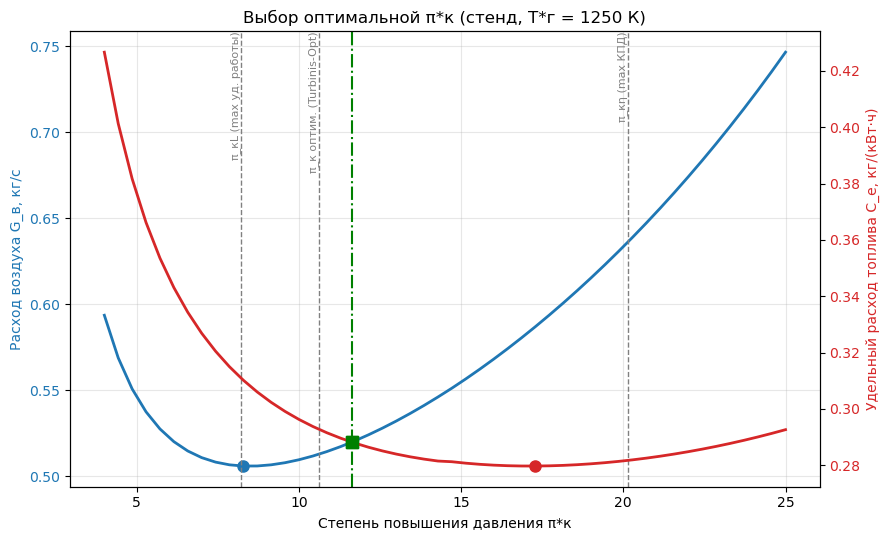

min G_в : π*к = 8.29, G_в = 0.506 кг/с
min C_e : π*к = 17.29, C_e = 0.280 кг/(кВт·ч), η_e = 0.298
пересечение линий на графике: π*к = 11.63, G_в = 0.520 кг/с, C_e = 0.288 кг/(кВт·ч)


In [35]:
# 5. Выбор оптимальной степени повышения давления в компрессоре ГТУ
import matplotlib.pyplot as plt

# точки π_кL и π_кη из п. 2.2
_точки = {"π_кL (max уд. работы)": π_кL_полн, "π_кη (max КПД)": π_кη_полн, "π_к оптим. (Turbinis-Opt)": π_к_оптим}

i_G = np.argmin(G_в)  # min расхода воздуха
i_C = np.argmin(C_e)  # min удельного расхода топлива

fig, ax1 = plt.subplots(figsize=(9, 5.5))
цвет_G, цвет_C = "tab:blue", "tab:red"

ax1.plot(π_к_полн, G_в, color=цвет_G, lw=2, label="G_в")
ax1.set_xlabel("Степень повышения давления π*к")
ax1.set_ylabel("Расход воздуха G_в, кг/с", color=цвет_G)
ax1.tick_params(axis="y", labelcolor=цвет_G)
ax1.plot(π_к_полн[i_G], G_в[i_G], "o", color=цвет_G, ms=8)

ax2 = ax1.twinx()
ax2.plot(π_к_полн, C_e, color=цвет_C, lw=2, label="C_e")
ax2.set_ylabel("Удельный расход топлива C_e, кг/(кВт·ч)", color=цвет_C)
ax2.tick_params(axis="y", labelcolor=цвет_C)
ax2.plot(π_к_полн[i_C], C_e[i_C], "o", color=цвет_C, ms=8)

# --- Точка пересечения линий В ТОМ ВИДЕ, как они нарисованы ---
# У G_в и C_e разные оси, поэтому переводим обе кривые в координаты графика
# (доля высоты от 0 до 1 по своей оси) и ищем, где эти линии совпадают.
# Пересечение зависит от пределов осей: меняете ylim -> меняется и точка.
lo1, hi1 = ax1.get_ylim()
lo2, hi2 = ax2.get_ylim()
y1 = (G_в - lo1) / (hi1 - lo1)
y2 = (C_e - lo2) / (hi2 - lo2)
разн = y1 - y2
идx = np.where(np.sign(разн[:-1]) * np.sign(разн[1:]) < 0)[0]
π_лев, π_прав = sorted(
    (π_к_полн[i_G], π_к_полн[i_C])
)  # пересечение ищем между двумя минимумами
пересечения = []
for j in идx:
    t = разн[j] / (разн[j] - разн[j + 1])  # линейная интерполяция
    π_x = π_к_полн[j] + t * (π_к_полн[j + 1] - π_к_полн[j])
    if not (π_лев <= π_x <= π_прав):
        continue  # отбрасываем краевые совпадения (артефакт масштаба)
    G_x = G_в[j] + t * (G_в[j + 1] - G_в[j])
    C_x = C_e[j] + t * (C_e[j + 1] - C_e[j])
    пересечения.append((π_x, G_x, C_x))

for название, π in _точки.items():
    ax1.axvline(π, color="gray", ls="--", lw=1)
    ax1.text(
        π,
        ax1.get_ylim()[1],
        название,
        rotation=90,
        va="top",
        ha="right",
        fontsize=8,
        color="gray",
    )

for π_x, G_x, C_x in пересечения:
    ax1.axvline(π_x, color="green", ls="-.", lw=1.5)
    ax1.plot(π_x, G_x, "s", color="green", ms=8)  # маркер на кривой G_в
    ax2.plot(π_x, C_x, "s", color="green", ms=8)  # и на кривой C_e

ax1.grid(alpha=0.3)
ax1.set_title(
    f"Выбор оптимальной π*к ({'полёт' if тип == 1 else 'стенд'}, T*г = {T_г_полн:.0f} К)"
)
fig.tight_layout()
plt.show()

print(f"min G_в : π*к = {π_к_полн[i_G]:.2f}, G_в = {G_в[i_G]:.3f} кг/с")
print(
    f"min C_e : π*к = {π_к_полн[i_C]:.2f}, C_e = {C_e[i_C]:.3f} кг/(кВт·ч), η_e = {η_e[i_C]:.3f}"
)
for π_x, G_x, C_x in пересечения:
    print(
        f"пересечение линий на графике: π*к = {π_x:.2f}, G_в = {G_x:.3f} кг/с, C_e = {C_x:.3f} кг/(кВт·ч)"
    )

In [36]:
# 5.1 Выбор расчётной точки
# "оптимум"     - рекомендуемый вариант многокритериальной оптимизации: π*к = π_к_оптим (см. Turbinis-Opt)
# "G_в"         - минимум расхода воздуха
# "C_e"         - минимум удельного расхода топлива
# "пересечение" - точка пересечения линий на графике
выбор = "C_e"

if выбор == "оптимум":
    π_к_выб = π_к_оптим
elif выбор == "G_в":
    π_к_выб = π_к_полн[i_G]
elif выбор == "C_e":
    π_к_выб = π_к_полн[i_C]
elif выбор == "пересечение":
    if not пересечения:
        raise ValueError("Линии на графике не пересекаются - выберите 'G_в' или 'C_e'")
    π_к_выб = пересечения[0][0]
else:
    raise ValueError(f"Неизвестный выбор: {выбор!r}")

# все параметры цикла пересчитываем точно в выбранной π_к (она может быть между узлами сетки)
р = calc_tvd(π_к_выб)
G_в_выб = N_в / р["N_в_уд"]  # кг/с
C_e_выб = р["g_m"] * (1 - g_ут - g_охл) * 3600 / (р["N_в_уд"] / 1e3)  # кг/(кВт·ч), на N_в
η_e_выб = 3600 / (C_e_выб * Q_н_р)

print(f"выбрана точка: {выбор}")
print(
    f"π*к = {π_к_выб:.2f}, G_в = {G_в_выб:.3f} кг/с, C_e = {C_e_выб:.3f} кг/(кВт·ч), η_e = {η_e_выб:.3f}"
)
print(
    f"π*т = {р['π_т']:.2f}, T*т = {р['T_т']:.1f} К, L_т = {р['L_т']/1e3:.1f} кДж/кг, "
    f"N_в.уд = {р['N_в_уд']/1e3:.1f} кВт·с/кг (N_e.уд с тягой сопла = {р['N_e_уд']/1e3:.1f}, не используется)"
)

выбрана точка: C_e
π*к = 17.29, G_в = 0.587 кг/с, C_e = 0.280 кг/(кВт·ч), η_e = 0.298
π*т = 15.36, T*т = 637.9 К, L_т = 646.5 кДж/кг, N_в.уд = 187.4 кВт·с/кг (N_e.уд с тягой сопла = 197.4, не используется)


In [37]:
# 6. Выбор частоты вращения и диаметра турбины (методичка, стр. 48-51)
# 6.1. Выбор частоты вращения по площади за турбиной
G_г = G_в_выб  # расход газа через турбину, G_г ≈ G_в (стр. 48)

# статические параметры за турбиной (нужны статические: v_т = R T_т / p_т)
k_т_вых = calc_k_kerosene(р["T_т"], р["α"])
T_т = р["T_т"] / (1 + (k_т_вых - 1) / 2 * M_т**2)  # T_т = T*т / (1 + (k-1)/2 M²)
p_т = π_с * p_а  # π_с = p_т / p_а (стр. 25)
c_т = M_т * np.sqrt(k_т_вых * R * T_т)  # скорость газа за турбиной
c_т_а = c_т  # c_т.а ≈ c_т
v_т = R * T_т / p_т  # удельный объём газа за турбиной, м³/кг

F_т = G_г * v_т / c_т_а  # м²
K_n = 6.8e-6  # F_т в м², n в об/мин, σ_л в МПа
σ_л_доп = 160  # МПа: стац./трансп. ГТУ 120...200, особо напряжённые авиац. > 300

n_т_max = np.sqrt(σ_л_доп / (K_n * F_т))  # об/мин
l_т_to_D_т = 0.250586  # l_т/D_т: рекомендуемый вариант оптимизации (диапазон книги 1/4...1/3.5, до 1/3; было 0.2679)
D_т = np.sqrt(F_т / (np.pi * l_т_to_D_т))  # средний диаметр, м
u_т = np.pi * D_т * n_т_max / 60  # окружная скорость на среднем радиусе, м/с

print(
    f"T_т = {T_т:.1f} К, p_т = {p_т/1e3:.1f} кПа, c_т = {c_т:.1f} м/с, v_т = {v_т:.3f} м³/кг"
)
print(f"F_т = {F_т:.4f} м², D_т = {D_т*1e3:.0f} мм, l_т = {l_т_to_D_т*D_т*1e3:.0f} мм")
print(f"n_т max = {n_т_max:.0f} об/мин, u_т = {u_т:.0f} м/с (при σ_л = {σ_л_доп} МПа)")

T_т = 632.8 К, p_т = 105.4 кПа, c_т = 102.0 м/с, v_т = 1.726 м³/кг
F_т = 0.0099 м², D_т = 112 мм, l_т = 28 мм
n_т max = 48682 об/мин, u_т = 286 м/с (при σ_л = 160 МПа)


In [38]:
# 6.2. Выбор частоты вращения по относительной длине лопаток
# задаёмся u_т и l_т/D_т -> получаем напряжение в лопатках
K_u = K_n * 60**2 / np.pi  # ≈ 7.8e-3
u_т_62 = 350  # м/с: стац. ГТУ 250...350, трансп. и авиац. 300...400, короткие лопатки 400...500
σ_л_62 = K_u * l_т_to_D_т * u_т_62**2  # МПа
D_т_62 = np.sqrt(G_г * v_т / (np.pi * l_т_to_D_т * c_т_а))  # то же, что D_т из 6.1
n_т_max_62 = 60 * u_т_62 / (np.pi * D_т_62)  # об/мин

print(f"K_u = {K_u:.2e}, D_т = {D_т_62*1e3:.0f} мм")
print(f"u_т = {u_т_62} м/с -> σ_л = {σ_л_62:.0f} МПа, n_т max = {n_т_max_62:.0f} об/мин")
if σ_л_62 > σ_л_доп:
    print(f"ВНИМАНИЕ: σ_л = {σ_л_62:.0f} МПа > допустимого {σ_л_доп} МПа - уменьшите u_т или l_т/D_т")

# проверка по частоте вращения вала нагрузки (если задана), стр. 51
n_н = None  # об/мин, например частота вала нагрузки
if n_н is not None:
    σ_л_н = K_n * n_н**2 * F_т
    print(f"при n_т = n_н = {n_н} об/мин: σ_л = {σ_л_н:.0f} МПа")
    if n_т_max > n_н:
        print("n_т max > n_н -> принимаем n_т = n_н (или увеличиваем D_т и снижаем l_т/D_т)")
    else:
        print("n_т max < n_н -> нагрузку через мультипликатор")

K_u = 7.79e-03, D_т = 112 мм
u_т = 350 м/с -> σ_л = 239 МПа, n_т max = 59524 об/мин
ВНИМАНИЕ: σ_л = 239 МПа > допустимого 160 МПа - уменьшите u_т или l_т/D_т


In [39]:
# 7. Сводная таблица параметров в трёх характерных точках
import pandas as pd


def сводка(π):
    """Все основные параметры цикла и турбины (п. 2-6) для одной π_к."""
    d = calc_tvd(π)
    T_к, _ = calc_compressor(π)
    G = N_в / d["N_в_уд"]
    C = d["g_m"] * (1 - g_ут - g_охл) * 3600 / (d["N_в_уд"] / 1e3)

    # п. 6: статические параметры за турбиной, площадь, диаметр, частота
    k = calc_k_kerosene(d["T_т"], d["α"])
    T = d["T_т"] / (1 + (k - 1) / 2 * M_т**2)
    c = M_т * np.sqrt(k * R * T)
    v_ = R * T / (π_с * p_а)
    F = G * v_ / c
    D = np.sqrt(F / (np.pi * l_т_to_D_т))

    return {
        ("Цикл", "π*к", "-"): π,
        ("Цикл", "T*к", "К"): T_к,
        ("Цикл", "α", "-"): d["α"],
        ("Цикл", "g_m", "-"): d["g_m"],
        ("Цикл", "π*т", "-"): d["π_т"],
        ("Цикл", "η*т", "-"): d["η_т"],
        ("Цикл", "T*т", "К"): d["T_т"],
        ("Цикл", "L_к", "кДж/кг"): d["L_к"] / 1e3,
        ("Цикл", "L_т", "кДж/кг"): d["L_т"] / 1e3,
        ("Цикл", "c_с", "м/с"): d["c_с"],
        ("Удельные", "N_в.уд", "кВт·с/кг"): d["N_в_уд"] / 1e3,
        ("Удельные", "R_уд", "Н·с/кг"): d["R_уд"],
        ("Удельные", "N_e.уд", "кВт·с/кг"): d["N_e_уд"] / 1e3,
        ("Экономичность", "C_e", "кг/(кВт·ч)"): C,
        ("Экономичность", "η_e", "-"): 3600 / (C * Q_н_р),
        ("Расходы", "G_в", "кг/с"): G,
        ("Расходы", "G_т.ч", "кг/ч"): d["g_m"] * (1 - g_ут - g_охл) * G * 3600,
        ("Турбина", "T_т (стат.)", "К"): T,
        ("Турбина", "c_т", "м/с"): c,
        ("Турбина", "v_т", "м³/кг"): v_,
        ("Турбина", "F_т", "см²"): F * 1e4,
        ("Турбина", "D_т", "мм"): D * 1e3,
        ("Турбина", "l_т", "мм"): l_т_to_D_т * D * 1e3,
        ("Турбина", "n_т max (6.1)", "об/мин"): np.sqrt(σ_л_доп / (K_n * F)),
        ("Турбина", "n_т max (6.2)", "об/мин"): 60 * u_т_62 / (np.pi * D),
    }


точки = {
    "оптимум": π_к_оптим,
    "min G_в": π_к_полн[i_G],
    "min C_e": π_к_полн[i_C],
    "пересечение": пересечения[0][0] if пересечения else np.nan,
}
табл = pd.DataFrame(
    {имя: сводка(π) for имя, π in точки.items() if not np.isnan(π)}
)
табл.index.names = ["раздел", "параметр", "ед."]
# отмечаем выбранную в п. 5.1 точку
выбранная = выбор if выбор in ("оптимум", "пересечение") else f"min {выбор}"
табл = табл.rename(columns={выбранная: f"► {выбранная} (выбрана)"})

print(
    f"N_в (на валу) = {N_в/1e3:.0f} кВт, T*г = {T_г_полн:.0f} К, σ_л = {σ_л_доп} МПа, "
    f"u_т (6.2) = {u_т_62} м/с, l_т/D_т = {l_т_to_D_т:.3f}, {'полёт' if тип == 1 else 'стенд'}"
)
# большие числа (об/мин) - целыми, остальные - 4 значащие цифры
табл.style.format(lambda x: f"{x:.0f}" if abs(x) >= 1000 else f"{x:.4g}")

N_в (на валу) = 110 кВт, T*г = 1250 К, σ_л = 160 МПа, u_т (6.2) = 350 м/с, l_т/D_т = 0.251, стенд
